# M03: Nghiên cứu bóc tách tiền xử lý (Preprocessing ablation analysis P0 → P3)

## 1. Thiết lập môi trường và nạp dữ liệu thực nghiệm

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Cấu hình đường dẫn thư mục gốc
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "vietnamese-news-topic-discovery" else Path(".").resolve()
RESULTS_DIR = PROJECT_ROOT / "results" / "kmeans"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình giao diện biểu đồ
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

## 2. Bảng tổng hợp kết quả đo lường định lượng ($K=9$)

In [2]:
metrics_path = RESULTS_DIR / "m03_preprocessing_ablation_metrics.csv"
metrics_df = pd.read_csv(metrics_path)

# Hiển thị các cột cốt lõi
display_cols = [
    "variant_id",
    "variant_name",
    "vocab_size",
    "val_sparsity_pct",
    "val_oov_rate_pct",
    "val_mean_active_terms",
    "silhouette_score",
    "davies_bouldin_index",
    "calinski_harabasz_score",
    "purity",
    "nmi",
    "ari",
    "stability_ari_mean",
    "compound_keyword_ratio_pct",
    "stopword_keyword_ratio_pct",
    "topic_diversity_top10",
]

styled = metrics_df[display_cols].style.format({
    "val_sparsity_pct": "{:.2f}%".format,
    "val_oov_rate_pct": "{:.2f}%".format,
    "val_mean_active_terms": "{:.1f}".format,
    "silhouette_score": "{:.4f}".format,
    "davies_bouldin_index": "{:.4f}".format,
    "calinski_harabasz_score": "{:.2f}".format,
    "purity": "{:.2%}".format,
    "nmi": "{:.4f}".format,
    "ari": "{:.4f}".format,
    "stability_ari_mean": "{:.4f}".format,
    "compound_keyword_ratio_pct": "{:.1f}%".format,
    "stopword_keyword_ratio_pct": "{:.1f}%".format,
    "topic_diversity_top10": "{:.4f}".format,
}).highlight_max(
    subset=["purity", "nmi", "ari", "stability_ari_mean", "compound_keyword_ratio_pct", "topic_diversity_top10"],
    color="#4a69d6"
).highlight_min(
    subset=["davies_bouldin_index", "val_oov_rate_pct", "stopword_keyword_ratio_pct"],
    color="#4a69d6"
)

styled

,variant_id,variant_name,vocab_size,val_sparsity_pct,val_oov_rate_pct,val_mean_active_terms,silhouette_score,davies_bouldin_index,calinski_harabasz_score,purity,nmi,ari,stability_ari_mean,compound_keyword_ratio_pct,stopword_keyword_ratio_pct,topic_diversity_top10
0,P0,P0_minimal,17983,98.34%,9.86%,299.3,0.0193,5.7112,13.15,83.61%,0.6652,0.5457,0.8599,0.0%,9.6%,0.9000
1,P1,P1_normalized,15285,98.17%,11.04%,279.9,0.0186,5.5708,14.17,81.52%,0.6503,0.5161,0.8267,0.0%,9.6%,0.8778
2,P2,P2_segmented,20000,98.79%,11.97%,241.8,0.0181,6.1151,11.50,81.60%,0.6494,0.4958,0.8186,32.6%,18.5%,0.9222
3,P3,P3_no_stopwords,20000,99.05%,2.56%,190.8,0.0190,6.1566,11.38,87.28%,0.7004,0.5925,0.8211,43.7%,0.0%,0.9556


## 3. Trực quan hóa nghiên cứu và nghịch lý chỉ số nội tại

### 3.1. So sánh chỉ số ngoại vi và độ ổn định đa seed

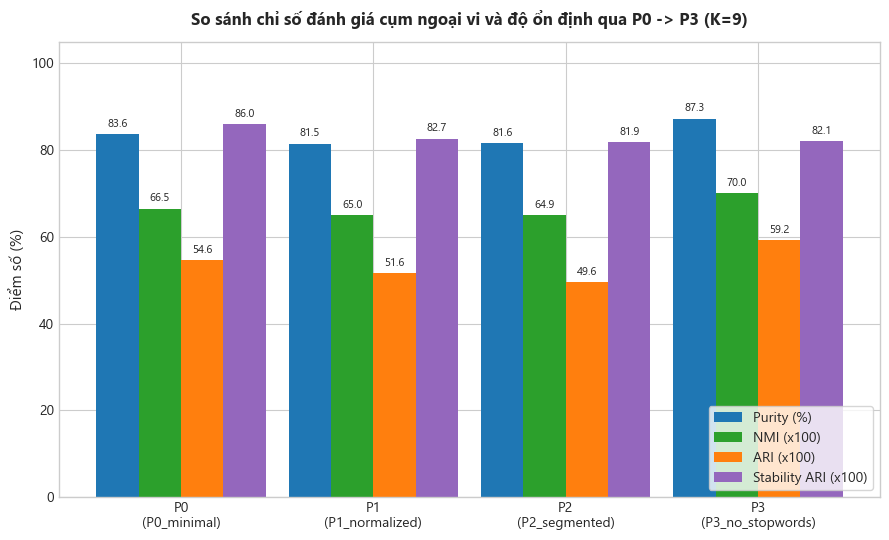

In [3]:
variants = metrics_df["variant_id"].tolist()
labels = [f"{vid}\n({vname})" for vid, vname in zip(variants, metrics_df["variant_name"])]
x = np.arange(len(variants))
width = 0.22

fig, ax = plt.subplots(figsize=(9, 5.5))
rects1 = ax.bar(x - 1.5 * width, metrics_df["purity"] * 100, width, label="Purity (%)", color="#1f77b4")
rects2 = ax.bar(x - 0.5 * width, metrics_df["nmi"] * 100, width, label="NMI (x100)", color="#2ca02c")
rects3 = ax.bar(x + 0.5 * width, metrics_df["ari"] * 100, width, label="ARI (x100)", color="#ff7f0e")
rects4 = ax.bar(x + 1.5 * width, metrics_df["stability_ari_mean"] * 100, width, label="Stability ARI (x100)", color="#9467bd")

ax.set_title("So sánh chỉ số đánh giá cụm ngoại vi và độ ổn định qua P0 -> P3 (K=9)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Điểm số (%)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(0, 105)
ax.legend(loc="lower right", frameon=True)

for rects in [rects1, rects2, rects3, rects4]:
    for bar in rects:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03_ablation_metrics_comparison.png", dpi=300)
plt.show()

### 3.2. Nghịch lý chỉ số nội tại
- P1 đạt Davies-Bouldin tốt nhất (5.5708) và Calinski-Harabasz cao nhất (14.17), nhưng Purity và NMI lại thấp nhất (81.52% và 0.6503).
- **Nguyên nhân toán học:** Ở P0 và P1, các âm tiết đơn lẻ tần suất cao (`các`, `của`, `người`, `và`) đóng vai trò "trọng lực giả", kéo các vector tài liệu lại gần nhau trong không gian Euclid đa chiều, tạo ảo giác co cụm chặt.
- **Nguyên nhân ngữ nghĩa:** Các cụm hình thành bị vỡ vụn nghĩa (âm tiết đơn què cụt) và ngập tràn từ dừng. Khi loại bỏ từ dừng ở P3, vector tỏa rộng theo ngữ nghĩa thực tế: DBI tăng nhẹ lên 6.1566 nhưng Purity tăng vọt lên **87.28%** và ARI tăng vọt lên **0.5925**.

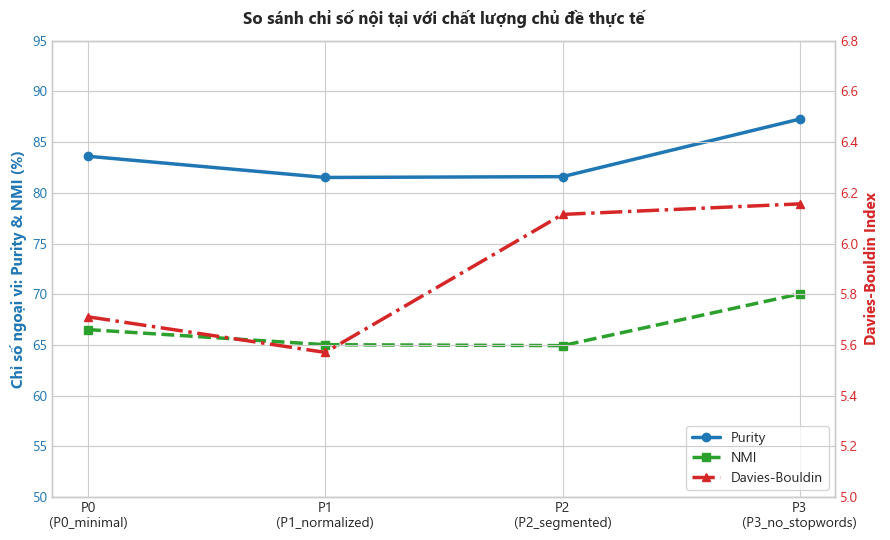

In [4]:
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax2 = ax1.twinx()

color_pur = "#1f77b4"
color_dbi = "#d62728"
color_nmi = "#2ca02c"

l1 = ax1.plot(x, metrics_df["purity"] * 100, marker="o", color=color_pur, linewidth=2.5, label="Purity")
l2 = ax1.plot(x, metrics_df["nmi"] * 100, marker="s", color=color_nmi, linewidth=2.5, linestyle="--", label="NMI")
ax1.set_ylabel("Chỉ số ngoại vi: Purity & NMI (%)", color=color_pur, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_pur)
ax1.set_ylim(50, 95)

l3 = ax2.plot(x, metrics_df["davies_bouldin_index"], marker="^", color=color_dbi, linewidth=2.5, linestyle="-.", label="Davies-Bouldin")
ax2.set_ylabel("Davies-Bouldin Index", color=color_dbi, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_dbi)
ax2.set_ylim(5.0, 6.8)

ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=10)
ax1.set_title("So sánh chỉ số nội tại với chất lượng chủ đề thực tế", fontsize=12, fontweight="bold", pad=12)

lines = l1 + l2 + l3
leg_labels = [l.get_label() for l in lines]
ax1.legend(lines, leg_labels, loc="lower right", frameon=True)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03_intrinsic_vs_extrinsic_paradox.png", dpi=300)
plt.show()

### 3.3. Chất lượng diễn giải từ vựng
- **P0/P1:** 0.0% từ ghép trong top 15, các cụm chứa nhiều âm tiết bị băm nhỏ (`phiếu`, `lãi`, `bác`, `sĩ`).
- **P2:** Tách từ giúp từ ghép tăng vọt lên 32.59% (`bác_sĩ`, `điều_trị`), nhưng vẫn bị ô nhiễm bởi 18.52% từ dừng.
- **P3:** Lọc từ dừng triệt tiêu hoàn toàn ô nhiễm (0.00% từ dừng), đẩy tỷ lệ từ ghép lên **43.70%** và đa dạng từ khóa lên **0.9556**.

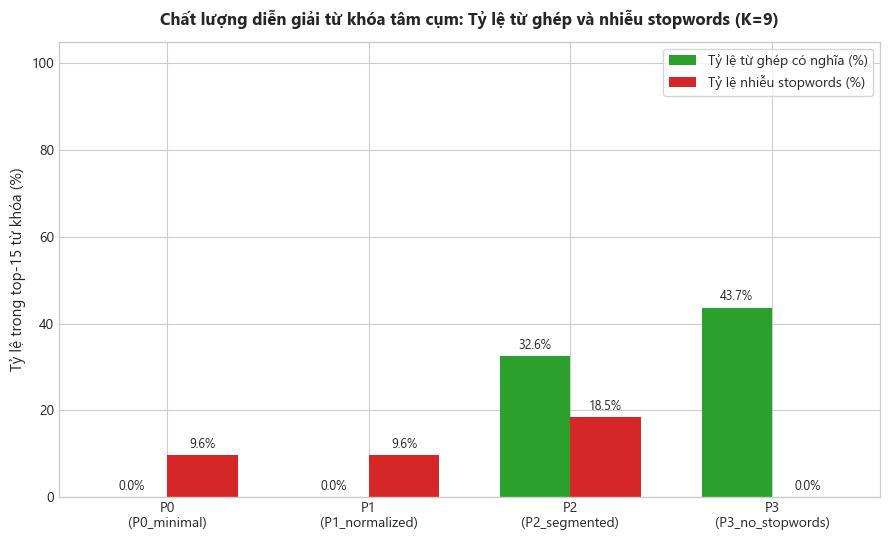

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
bar_width = 0.35
b1 = ax.bar(x - bar_width / 2, metrics_df["compound_keyword_ratio_pct"], bar_width, label="Tỷ lệ từ ghép có nghĩa (%)", color="#2ca02c")
b2 = ax.bar(x + bar_width / 2, metrics_df["stopword_keyword_ratio_pct"], bar_width, label="Tỷ lệ nhiễu stopwords (%)", color="#d62728")

ax.set_title("Chất lượng diễn giải từ khóa tâm cụm: Tỷ lệ từ ghép và nhiễu stopwords (K=9)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Tỷ lệ trong top-15 từ khóa (%)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(0, 105)
ax.legend(loc="upper right", frameon=True)

for bar in b1:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
for bar in b2:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03_lexical_interpretability.png", dpi=300)
plt.show()

## 4. Kiểm tra độ nhạy với mốc đối chiếu $K=7$
Đối chiếu với $K=7$ tương ứng 7 nhãn chuyên mục `category_gold` gốc của bộ dữ liệu.

purity             nmi             ari          \
k                7       9       7       9       7       9   
variant_id                                                   
P0          0.7843  0.8361  0.6420  0.6652  0.5505  0.5457   
P1          0.8109  0.8152  0.6683  0.6503  0.6066  0.5161   
P2          0.8152  0.8160  0.6788  0.6494  0.5869  0.4958   
P3          0.8210  0.8728  0.6889  0.7004  0.6239  0.5925   

           stopword_keyword_ratio_pct         
k                                   7      9  
variant_id                                    
P0                              13.33   9.63  
P1                              12.38   9.63  
P2                              21.90  18.52  
P3                               0.00   0.00

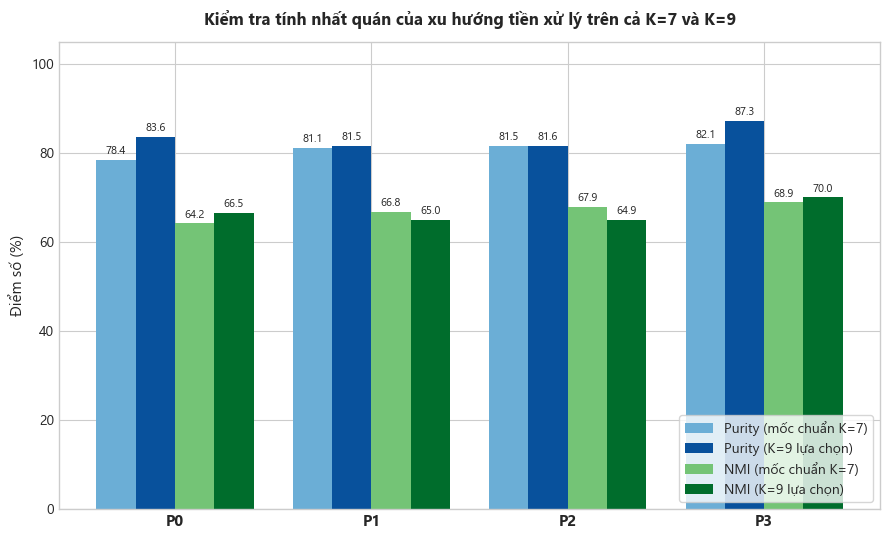

In [6]:
sens_path = RESULTS_DIR / "m03_preprocessing_ablation_k7_sensitivity.csv"
sens_df = pd.read_csv(sens_path)

# Bảng đối chiếu K=7 vs K=9
sens_pivot = sens_df.pivot(index="variant_id", columns="k", values=["purity", "nmi", "ari", "stopword_keyword_ratio_pct"])
display(sens_pivot)

fig, ax = plt.subplots(figsize=(9, 5.5))
k7_data = sens_df[sens_df["k"] == 7].set_index("variant_id")
k9_data = sens_df[sens_df["k"] == 9].set_index("variant_id")

v_ids = ["P0", "P1", "P2", "P3"]
k7_purity = [k7_data.loc[v, "purity"] * 100 for v in v_ids]
k9_purity = [k9_data.loc[v, "purity"] * 100 for v in v_ids]
k7_nmi = [k7_data.loc[v, "nmi"] * 100 for v in v_ids]
k9_nmi = [k9_data.loc[v, "nmi"] * 100 for v in v_ids]

x_sens = np.arange(len(v_ids))
w = 0.2

r1 = ax.bar(x_sens - 1.5 * w, k7_purity, w, label="Purity (mốc chuẩn K=7)", color="#6baed6")
r2 = ax.bar(x_sens - 0.5 * w, k9_purity, w, label="Purity (K=9 lựa chọn)", color="#08519c")
r3 = ax.bar(x_sens + 0.5 * w, k7_nmi, w, label="NMI (mốc chuẩn K=7)", color="#74c476")
r4 = ax.bar(x_sens + 1.5 * w, k9_nmi, w, label="NMI (K=9 lựa chọn)", color="#006d2c")

ax.set_title("Kiểm tra tính nhất quán của xu hướng tiền xử lý trên cả K=7 và K=9", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Điểm số (%)", fontsize=11)
ax.set_xticks(x_sens)
ax.set_xticklabels(v_ids, fontsize=11, fontweight="bold")
ax.set_ylim(0, 105)
ax.legend(loc="lower right", frameon=True)

for rects in [r1, r2, r3, r4]:
    for bar in rects:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03_k7_vs_k9_sensitivity.png", dpi=300)
plt.show()

## 5. Dẫn chứng định tính từng cụm: So sánh P0 vs P3 ($K=9$)
Bảng so sánh trực quan cụ thể các cụm chủ đề giữa dữ liệu chưa qua xử lý (P0) và dữ liệu được tiền xử lý hoàn thiện (P3).

In [7]:
qual_path = RESULTS_DIR / "m03_qualitative_cluster_examples.csv"
qual_df = pd.read_csv(qual_path)

p0_sample = qual_df[qual_df["variant_id"] == "P0"][["cluster_id", "dominant_gold_category", "top10_keywords", "nearest_article_title"]]
p3_sample = qual_df[qual_df["variant_id"] == "P3"][["cluster_id", "dominant_gold_category", "top10_keywords", "nearest_article_title"]]

print("P0: Tiền xử lý tối giản (từ khóa vỡ vụn, dính từ dừng, lẫn chữ hoa)")
display(p0_sample.head(5))

print("\nP3: Tiền xử lý hoàn thiện (từ ghép chuyên ngành, sạch từ dừng)")
display(p3_sample.head(5))

P0: Tiền xử lý tối giản (từ khóa vỡ vụn, dính từ dừng, lẫn chữ hoa)


,cluster_id,dominant_gold_category,top10_keywords,nearest_article_title
0,0,Kinh doanh,"tăng, phiếu, lãi, USD, giảm, mức, giá, so, thị...",Lãi suất vay lên 16%: Doanh nghiệp ôm tiền mặt...
1,1,Khoa học công nghệ,"iPhone, Apple, Pro, Max, gập, 18, Duo, màn, ca...",3 iPhone cao cấp ra mắt tuần này: iPhone 18 Pr...
2,2,Giải trí,"diễn, những, phim, người, cô, năm, ảnh, sự, vi...",Mỹ Anh: Không đợi thành công trong nước rồi mớ...
3,3,Giáo dục,"học, giáo, sinh, dục, trường, Trường, viên, Gi...",5 kỳ vọng lớn của ngành giáo dục năm học mới
4,4,Kinh doanh,"doanh, triển, nghiệp, công, sản, động, phát, t...",Từ thương mại đến hút dòng vốn chất lượng cao:...



P3: Tiền xử lý hoàn thiện (từ ghép chuyên ngành, sạch từ dừng)


,cluster_id,dominant_gold_category,top10_keywords,nearest_article_title
27,0,Giải trí,"cô, phim, anh, khán_giả, không, diễn_viên, tôi...",Mỹ Anh: Không đợi thành công trong nước rồi mớ...
28,1,Thể thao,"asiad, nữ, u23, nam, giành, thi_đấu, việt_nam,...",Xác định 8 đội vào tứ kết bóng đá nữ Asiad 20
29,2,Khoa học công nghệ,"iphone, apple, pro, máy, dùng, màn_hình, max, ...","Toàn cảnh thông tin hot nhất về iPhone 18 Pro,..."
30,3,Sức khỏe,"bác_sĩ, bệnh, điều_trị, bệnh_viện, người_bệnh,...",5 điều cần biết để giữ thận khỏe
31,4,Thể thao,"trận, đội, bóng, cầu_thủ, hlv, cup, thắng, sân...",HLV tuyển Philippines: 'Chúng tôi không đáng t...
